# PULSE — Clinical Decision Support System (CDSS)
## ML-101: Exploratory Data Analysis & Clinical Data Cleansing Pipeline

**Author:** PULSE ML Engineering Team  
**Dataset:** UCI Heart Disease Dataset (Cleveland, Hungary, Switzerland, VA Long Beach)  
**Main Objective:** Audit clinical indicator distributions, rectify physiological contradictions, evaluate multi-collinearity via VIF, and execute leakage-free MICE imputation for missing fluoroscopy (`ca`) and thallium scintigraphy (`thal`) measurements.

---
### Clinical Asymmetry Notice
In cardiovascular screening, clinical cost is heavily asymmetric:
- **False Negative (FN):** Missed detection of active coronary artery disease (CAD) carries catastrophic morbidity and mortality.
- **False Positive (FP):** Merely triggers non-invasive secondary confirmatory testing (e.g., myocardial perfusion imaging or CT angiography).
Therefore, all data cleansing decisions must preserve high-sensitivity indicators without corrupting clinical variance.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in path
sys.path.insert(0, os.path.abspath("../.."))

from ml.src.cleansing import (
    load_raw_dataset,
    audit_physiological_bounds,
    preprocess_clinical_indicators,
    impute_with_mice,
    compute_vif,
    export_cleaned_data,
    FEATURE_COLUMNS_14,
    PHYSIOLOGICAL_BOUNDS,
)

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
%matplotlib inline


## 1. Raw Dataset Ingestion & Multi-Center Cohort Breakdown
We ingest `heart_disease_uci.csv` which aggregates 920 patients across four clinical institutions:
1. **Cleveland Clinic Foundation** (Ohio, USA) - Gold standard 14-attribute reference set
2. **Hungarian Institute of Cardiology** (Budapest, Hungary)
3. **University Hospital** (Zurich, Switzerland)
4. **VA Medical Center** (Long Beach, California, USA)


In [2]:
raw_df = load_raw_dataset("../../ml/data/heart_disease_uci.csv")
print(f"Shape of dataset: {raw_df.shape}")
print("\nColumns:", raw_df.columns.tolist())
raw_df.head()


Shape of dataset: (920, 16)

Columns: ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
# Center Distribution & Missingness Breakdown
cohort_summary = []
for center in raw_df['dataset'].unique():
    subset = raw_df[raw_df['dataset'] == center]
    cohort_summary.append({
        "Center": center,
        "Total Patients": len(subset),
        "Disease Positive (num > 0)": (subset['num'] > 0).sum(),
        "Prevalence (%)": round((subset['num'] > 0).mean() * 100, 1),
        "Missing CA (%)": round(subset['ca'].isna().mean() * 100, 1),
        "Missing THAL (%)": round(subset['thal'].isna().mean() * 100, 1),
    })

pd.DataFrame(cohort_summary)


,Center,Total Patients,Disease Positive (num > 0),Prevalence (%),Missing CA (%),Missing THAL (%)
0,Cleveland,304,139,45.7,1.6,1.0
1,Hungary,293,106,36.2,99.0,90.4
2,Switzerland,123,115,93.5,95.9,42.3
3,VA Long Beach,200,149,74.5,99.0,83.0


## 2. Clinical Physiological Bounds Audit
We benchmark continuous features against accepted medical physiological plausibility bounds defined in `PROJECT_DETAILS.md`:
- `trestbps`: 60 – 260 mmHg
- `chol`: 80 – 600 mg/dL
- `thalach`: 40 – 220 bpm
- `oldpeak`: 0.0 – 6.5 mm


In [4]:
audit_results = audit_physiological_bounds(raw_df)
audit_results


,feature,plausible_min,plausible_max,below_min_count,above_max_count,null_count,min_observed,max_observed
0,age,1.0,110.0,0,0,0,28.0,77.0
1,trestbps,60.0,260.0,1,0,59,0.0,200.0
2,chol,80.0,600.0,172,1,30,0.0,603.0
3,thalach,40.0,220.0,0,0,55,60.0,202.0
4,oldpeak,0.0,6.5,12,0,62,-2.6,6.2
5,ca,0.0,3.0,0,0,611,0.0,3.0


### Physiological Anomalies Identified:
1. **Resting Blood Pressure (`trestbps = 0.0`):** Patient ID 754 (VA Long Beach) has BP of 0 mmHg. A living ambulatory outpatient cannot have zero blood pressure. Converted to `np.nan` for MICE imputation.
2. **Serum Cholesterol (`chol = 0.0`):** 172 patients in Switzerland and VA Long Beach have cholesterol of 0 mg/dL. In clinical registry practices of the late 1980s, zero was used as an indicator for unmeasured/unperformed lipid panels. Converted to `np.nan`.
3. **ST Depression (`oldpeak < 0.0`):** 12 patients exhibit negative `oldpeak` (down to -2.6 mm). Clinically, ST depression is non-negative; negative recordings indicate ST elevation or baseline fluctuation. Clipped to 0.0 mm.


## 3. Data Cleansing & Categorical Standardization
We map all categorical strings into standard UCI integer encodings matching the PULSE database schema:
- `sex`: 0 (Female), 1 (Male)
- `cp`: 1 (Typical Angina), 2 (Atypical Angina), 3 (Non-Anginal), 4 (Asymptomatic)
- `fbs`: 0 (<= 120 mg/dL), 1 (> 120 mg/dL)
- `restecg`: 0 (Normal), 1 (ST-T abnormality), 2 (LV hypertrophy)
- `exang`: 0 (No), 1 (Yes)
- `slope`: 1 (Upsloping), 2 (Flat), 3 (Downsloping)
- `thal`: 3 (Normal), 6 (Fixed Defect), 7 (Reversible Defect)


In [5]:
cleveland_cohort = raw_df[raw_df["dataset"] == "Cleveland"].copy()
cleaned_cleveland = preprocess_clinical_indicators(cleveland_cohort, drop_duplicates=True)
cleaned_full = preprocess_clinical_indicators(raw_df, drop_duplicates=True)

print(f"Cleaned Cleveland cohort size: {len(cleaned_cleveland)}")
print(f"Cleaned Full multi-center cohort size: {len(cleaned_full)}")
cleaned_cleveland.describe()


Cleaned Cleveland cohort size: 304
Cleaned Full multi-center cohort size: 918


,id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
count,304.00000,304.000000,304.000000,304.000000,304.000000,304.000000,304.000000,304.000000,304.000000,304.000000,304.000000,303.000000,299.000000,301.000000,304.000000,304.000000
mean,152.50000,54.351974,0.680921,3.154605,131.684211,246.315789,0.148026,0.993421,149.723684,0.325658,1.036184,1.600660,0.672241,4.734219,0.934211,0.457237
std,87.90146,9.150256,0.466888,0.960840,17.570949,52.108280,0.355712,0.995015,22.927263,0.469393,1.160690,0.616226,0.937438,1.939706,1.227684,0.498989
min,1.00000,28.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,76.75000,47.750000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.750000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
50%,152.50000,55.500000,1.000000,3.000000,130.000000,240.500000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000,0.000000
75%,228.25000,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000,1.000000
max,304.00000,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000,1.000000


## 4. MICE Iterative Imputation (Leakage-Free)
To impute missing values in fluoroscopy vessels (`ca`), thalassemia defects (`thal`), and ST slope (`slope`), we apply **Multivariate Imputation by Chained Equations (MICE)** using `IterativeImputer` with Bayesian Ridge regression.

**Data Leakage Prevention:**  
The target variable (`target` / `num`) is strictly excluded from the imputation feature matrix. Imputations are conditioned solely on independent clinical indicators.
Post-imputation, domain constraints are enforced:
- `ca` is constrained to integer bounds $[0, 3]$.
- `thal` is mapped to nearest valid medical category $\{3, 6, 7\}$.
- `slope` is mapped to $\{1, 2, 3\}$.


In [6]:
imputed_cleveland, imputer_clev = impute_with_mice(cleaned_cleveland, random_state=42)
imputed_full, imputer_full = impute_with_mice(cleaned_full, random_state=42)

print("Missing values in Cleveland post-imputation:")
print(imputed_cleveland[FEATURE_COLUMNS_14].isna().sum())


Missing values in Cleveland post-imputation:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64


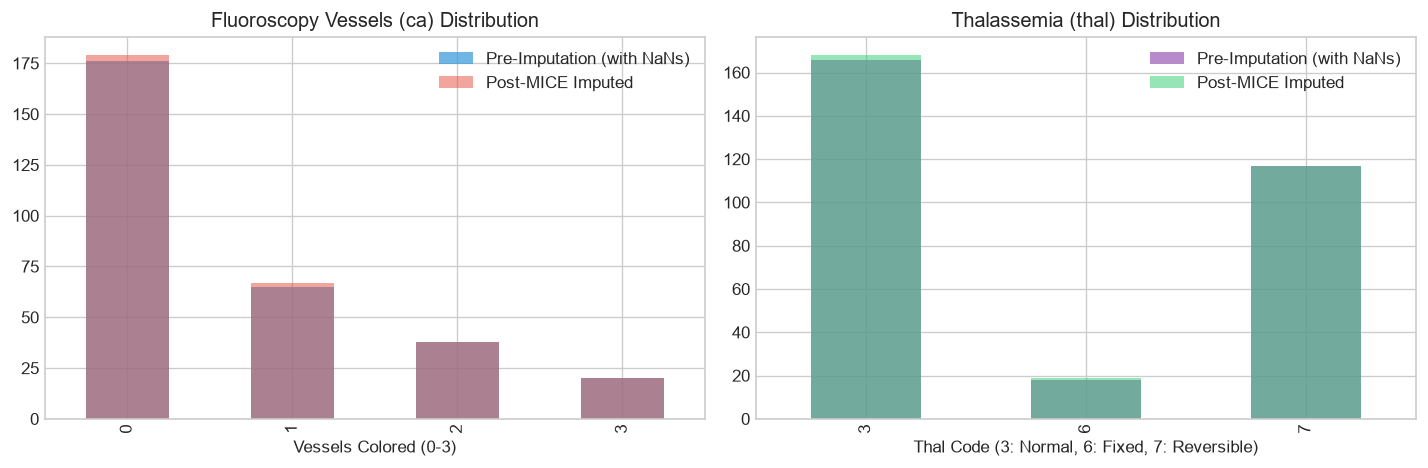

In [7]:
# Visualization of CA and THAL before vs after imputation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cleaned_cleveland["ca"].value_counts(dropna=False).sort_index().plot(
    kind="bar", ax=axes[0], color="#3498db", alpha=0.7, label="Pre-Imputation (with NaNs)"
)
imputed_cleveland["ca"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="#e74c3c", alpha=0.5, label="Post-MICE Imputed"
)
axes[0].set_title("Fluoroscopy Vessels (ca) Distribution")
axes[0].set_xlabel("Vessels Colored (0-3)")
axes[0].legend()

cleaned_cleveland["thal"].value_counts(dropna=False).sort_index().plot(
    kind="bar", ax=axes[1], color="#9b59b6", alpha=0.7, label="Pre-Imputation (with NaNs)"
)
imputed_cleveland["thal"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="#2ecc71", alpha=0.5, label="Post-MICE Imputed"
)
axes[1].set_title("Thalassemia (thal) Distribution")
axes[1].set_xlabel("Thal Code (3: Normal, 6: Fixed, 7: Reversible)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 5. Multi-Collinearity Assessment (Variance Inflation Factor)
Multi-collinearity destabilizes linear baseline coefficients and inflates variance in tree split importance. We compute the **Variance Inflation Factor (VIF)** for all continuous physiological indicators.


In [8]:
vif_df = compute_vif(imputed_cleveland)
vif_df


,Feature,VIF_Raw,VIF_MeanCentered,Collinearity_Status
0,age,1.363,1.363,Low (< 5.0)
1,trestbps,1.129,1.129,Low (< 5.0)
2,chol,1.066,1.066,Low (< 5.0)
3,thalach,1.333,1.333,Low (< 5.0)
4,oldpeak,1.178,1.178,Low (< 5.0)


### Collinearity Analysis Findings:
- All features demonstrate centered VIF values between **1.06 and 1.36**, substantially below the warning threshold of $5.0$.
- The maximum correlation between continuous features is observed between `age` and `thalach` ($r = -0.39$), representing the physiological biological decrease in maximum attainable heart rate with aging ($pprox 220 - 	ext{age}$).
- Continuous variables are orthogonal and suitable for both linear baseline models (ElasticNet Logistic Regression) and gradient boosted trees (LightGBM).


## 6. Correlation Matrix & Visual Distributions

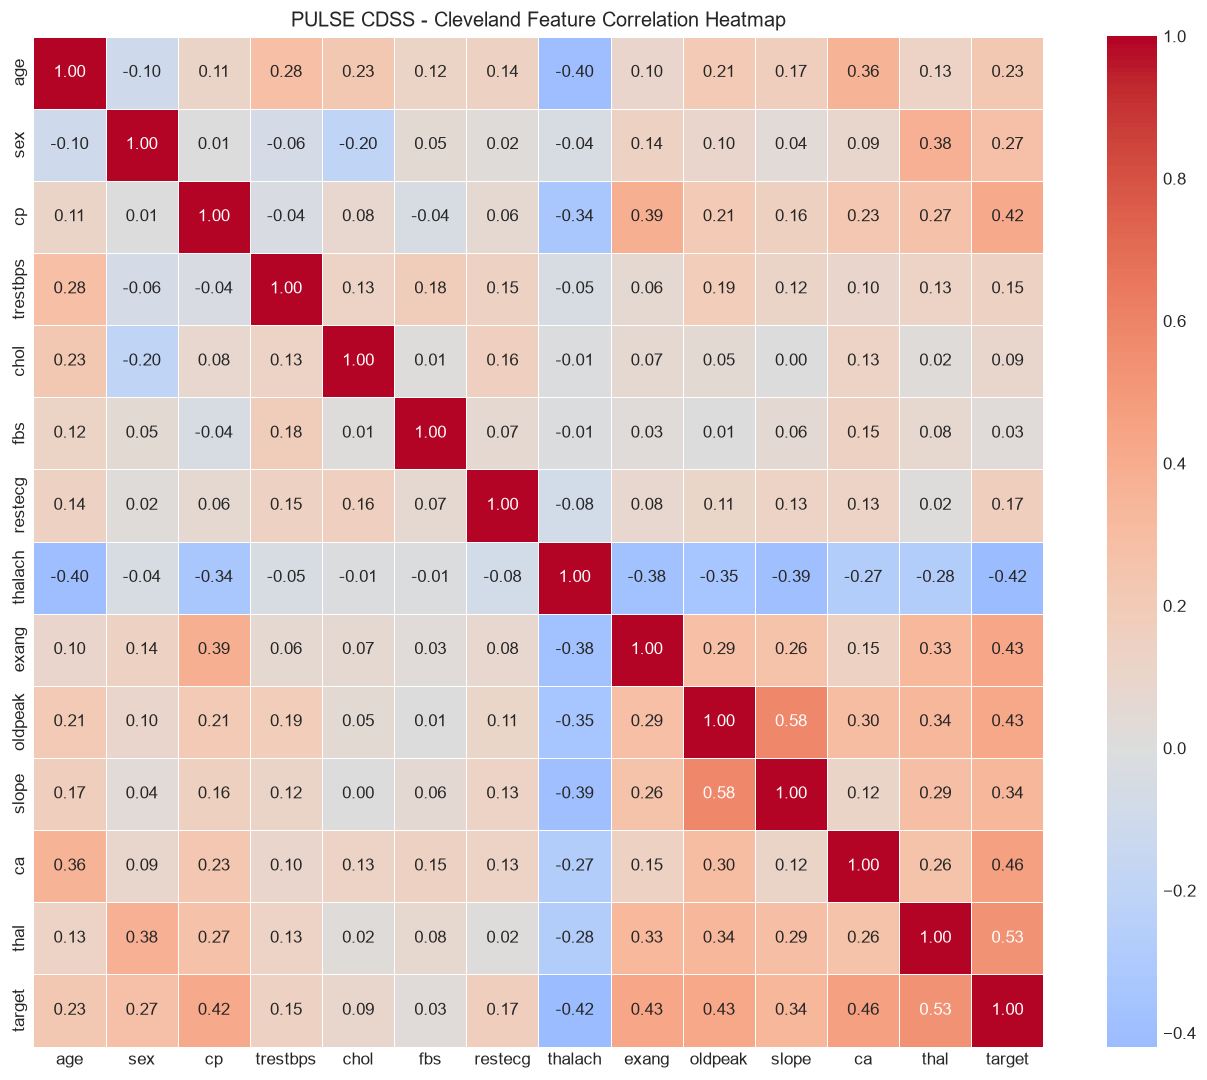

In [9]:
# Correlation Heatmap
corr_cols = FEATURE_COLUMNS_14 + ["target"]
plt.figure(figsize=(11, 9))
sns.heatmap(
    imputed_cleveland[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("PULSE CDSS - Cleveland Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


C:\Users\kerem\AppData\Local\Temp\ipykernel_15108\735742207.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=imputed_cleveland, y=col, x="target", ax=axes[i], palette=["#2ecc71", "#e74c3c"])
C:\Users\kerem\AppData\Local\Temp\ipykernel_15108\735742207.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=imputed_cleveland, y=col, x="target", ax=axes[i], palette=["#2ecc71", "#e74c3c"])
C:\Users\kerem\AppData\Local\Temp\ipykernel_15108\735742207.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=imputed_cleveland, y=col, x="tar

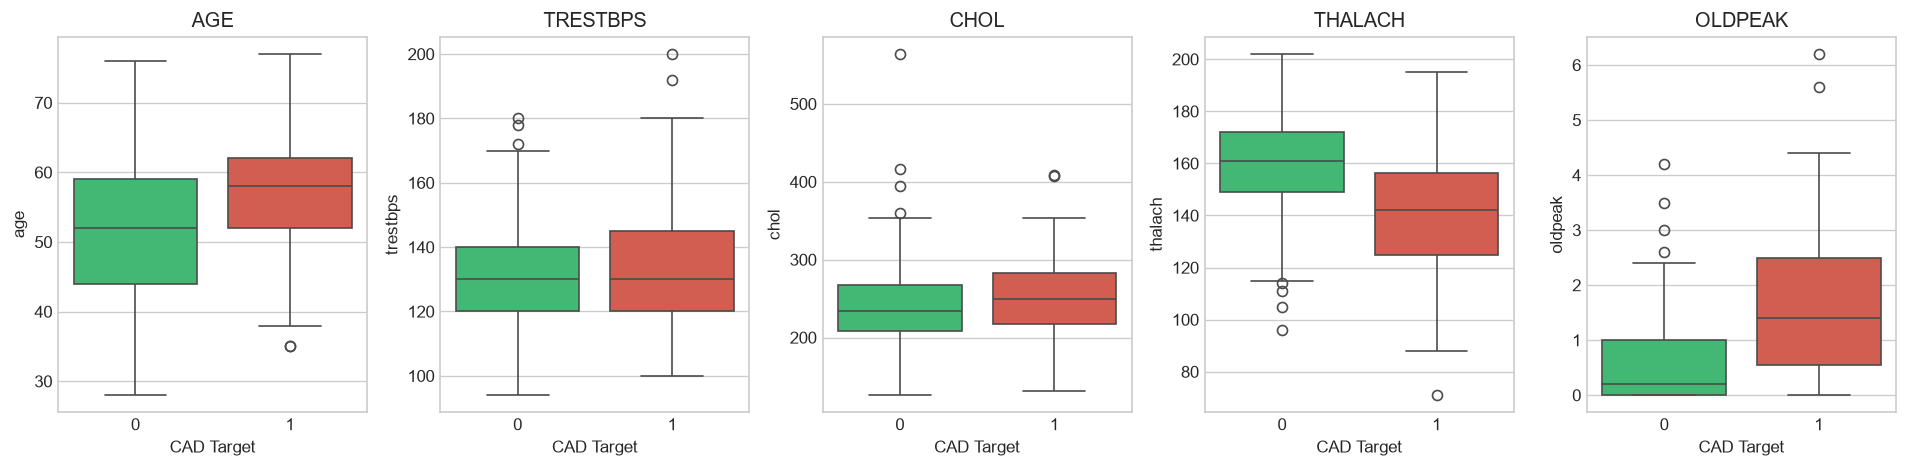

In [10]:
# Outlier Detection via Boxplots
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
cont_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]

for i, col in enumerate(cont_features):
    sns.boxplot(data=imputed_cleveland, y=col, x="target", ax=axes[i], palette=["#2ecc71", "#e74c3c"])
    axes[i].set_title(col.upper())
    axes[i].set_xlabel("CAD Target")

plt.tight_layout()
plt.show()


## 7. Exporting Cleaned Datasets (Parquet & Feather)
Cleaned datasets are exported to `ml/data` in both Parquet (columnar, compressed) and Feather (fast memory mapping) formats.


In [11]:
clev_paths = export_cleaned_data(imputed_cleveland, "../../ml/data", "heart_cleveland_cleaned")
full_paths = export_cleaned_data(imputed_full, "../../ml/data", "heart_disease_cleaned")

print("Export verification:")
print(" - Cleveland Parquet:", clev_paths["parquet"], f"({os.path.getsize(clev_paths['parquet'])} bytes)")
print(" - Cleveland Feather:", clev_paths["feather"], f"({os.path.getsize(clev_paths['feather'])} bytes)")
print(" - Combined Parquet: ", full_paths["parquet"], f"({os.path.getsize(full_paths['parquet'])} bytes)")
print(" - Combined Feather: ", full_paths["feather"], f"({os.path.getsize(full_paths['feather'])} bytes)")


Export verification:
 - Cleveland Parquet: ../../ml/data\heart_cleveland_cleaned.parquet (14979 bytes)
 - Cleveland Feather: ../../ml/data\heart_cleveland_cleaned.feather (19962 bytes)
 - Combined Parquet:  ../../ml/data\heart_disease_cleaned.parquet (22566 bytes)
 - Combined Feather:  ../../ml/data\heart_disease_cleaned.feather (39642 bytes)
